# 🏦 Practice — Loan Approval

A bank receives hundreds of loan applications every month. It wants a model that looks at an applicant's details and predicts whether the loan will be **approved (1)** or **not approved (0)**.

**Dataset:** `loan_approval.csv` — 500 applicants

| Column | Meaning |
|---|---|
| `applicant_id` | Application number |
| `age` | Age of the applicant |
| `monthly_income_k` | Monthly income in ₹ thousand |
| `credit_score` | Credit score (300–900) |
| `loan_amount_lakh` | Loan asked for, in ₹ lakh |
| `existing_loans` | Number of loans already running |
| `years_employed` | Years in the current job |
| `employment_type` | Salaried / Self-employed |
| `property_owner` | Owns a property: Yes / No |
| `approved` | **Target** — 1 = approved, 0 = not approved |
| `approved_amount_lakh` | Amount the bank finally gave (0 if not approved) |

Steps 1–5 are already done. **Your work starts at Step 6.**

## 📥 1. Load the data

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('loan_approval.csv')
df.head()

,applicant_id,age,employment_type,city_tier,annual_income,loan_amount_lakh,credit_score,existing_loans,years_at_job,approved
0,APP1001,58,Salaried,Tier-2,736000,24.2,718.0,0,25.0,1
1,APP1002,46,Salaried,Tier-2,282000,5.6,712.0,4,6.0,0
2,APP1003,48,Salaried,Tier-2,931000,15.5,513.0,2,NaN,0
3,APP1004,56,Salaried,Tier-1,1300000,34.1,682.0,1,16.0,1
4,APP1005,44,Salaried,Tier-1,533000,7.5,742.0,0,12.0,1


## 🧹 2. Clean the data

> **Flow:** drop the columns we will not use → fill missing values with the median

`approved_amount_lakh` is dropped because it is known only **after** the bank decides — it would give the answer away.

In [10]:
df = df.drop(columns=['applicant_id', 'loan_amount_lakh', 'employment_type', 'city_tier'])

df['credit_score'] = df['credit_score'].fillna(df['credit_score'].median())
df['years_at_job'] = df['years_at_job'].fillna(df['years_at_job'].median())

df.isnull().sum()

age               0
annual_income     0
credit_score      0
existing_loans    0
years_at_job      0
approved          0
dtype: int64

## 🎯 3. Features (X) and target (y)

In [11]:
X = df.drop(columns='approved')
y = df['approved']

## ✂️ 4. Train / test split

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 📏 5. Scale the features

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

---
# ✍️ Your turn

## 🤖 6. Build and train the model

Import `LogisticRegression`, create the model and train it on `X_train_scaled` and `y_train`.

In [14]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## 🔮 7. Predict

Predict for `X_test_scaled` and store the result in `y_pred`.

In [15]:
y_pred = model.predict(X_test_scaled)

## ✅ 8. Accuracy

Find the accuracy of the model with `accuracy_score`.

In [16]:
from sklearn.metrics import accuracy_score
score = accuracy_score(y_test, y_pred)
print(score)

0.84


## 🧮 9. Confusion matrix

Build the confusion matrix with `confusion_matrix`, then plot it as a heatmap with `annot=True`. Label the x-axis **Predicted** and the y-axis **Actual**.

In [17]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[30 11]
 [ 5 54]]


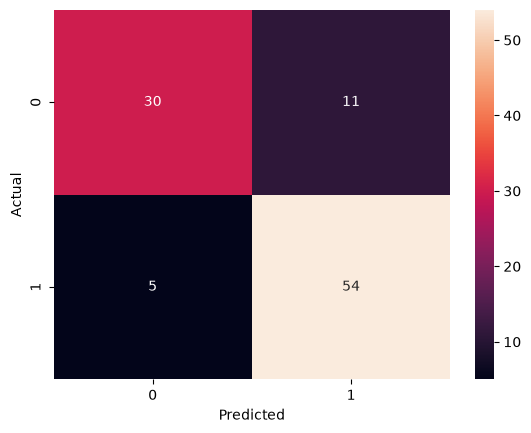

In [18]:
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

---
## 💬 Read your confusion matrix

Answer from the matrix you just made.

**Q1.** The test set has 100 applicants. For how many of them did the model make the right call?

*Your answer:* 

Acc. to the confusion matrix:

Actual \ Predicted	0 (Not approved)	1 (Approved)
0 (Not approved)	    30	                    11
1 (Approved)	         5	                    54

30 (True Negative) + 54 (True Positive) = 84 applicants

**Q2.** The bank manager is worried about giving loans to the wrong people. How many applicants did the model approve even though the bank actually **did not** approve them?

*Your answer:*

Actual = 0, Predicted = 1 (False Positive) → 11 applicants

**Q3.** How many applicants **were** approved by the bank, but the model said "not approved"?

*Your answer:*

Actual = 1, Predicted = 0 (False Negative)→ 5 applicants